# Exploratory Data Analysis (EDA): Melbourne Housing Snapshot

**Name:** Zainab Arshad | **Roll No.:** 013 | **Section:** 3A
**Dataset:** Melbourne Housing Snapshot (Kaggle), cleaned in Assignment 2
**Target variable:** Price (sale price of a property)
**Question:** Which features explain the sale price of a house in Melbourne?

In [22]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [23]:
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/zainabhafiza/melb-cleaned/melb_cleaned.csv


In [24]:
df = pd.read_csv("/kaggle/input/datasets/zainabhafiza/melb-cleaned/melb_cleaned.csv", parse_dates=["Date"])
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (13579, 31)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longitude,Regionname,Propertycount,SaleYear,SaleMonth,Month_sin,Month_cos,HouseAge,BathPerRoom,LandsizeZero,BuildingAreaMissing,YearBuiltMissing,AgeGroup
0,Abbotsford,85 Turner St,2,house,1480000.0,S,Biggin,2016-12-03,2.5,3067,2,1,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0,2016,12,-2.449294e-16,1.000000e+00,NaN,0.500000,0,1,1,NaN
1,Abbotsford,25 Bloomburg St,2,house,1035000.0,S,Biggin,2016-02-04,2.5,3067,2,1,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0,2016,2,8.660254e-01,5.000000e-01,116.0,0.500000,0,0,0,Historic
2,Abbotsford,5 Charles St,3,house,1465000.0,SP,Biggin,2017-03-04,2.5,3067,3,2,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0,2017,3,1.000000e+00,6.123234e-17,117.0,0.666667,0,0,0,Historic
3,Abbotsford,40 Federation La,3,house,850000.0,PI,Biggin,2017-03-04,2.5,3067,3,2,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0,2017,3,1.000000e+00,6.123234e-17,NaN,0.666667,0,1,1,NaN
4,Abbotsford,55a Park St,4,house,1600000.0,VB,Nelson,2016-06-04,2.5,3067,3,1,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0,2016,6,1.224647e-16,-1.000000e+00,2.0,0.250000,0,0,0,New


## Step 1: Understand the Dataset

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13579 entries, 0 to 13578
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Suburb               13579 non-null  object        
 1   Address              13579 non-null  object        
 2   Rooms                13579 non-null  int64         
 3   Type                 13579 non-null  object        
 4   Price                13579 non-null  float64       
 5   Method               13579 non-null  object        
 6   SellerG              13579 non-null  object        
 7   Date                 13579 non-null  datetime64[ns]
 8   Distance             13579 non-null  float64       
 9   Postcode             13579 non-null  int64         
 10  Bedroom2             13579 non-null  int64         
 11  Bathroom             13579 non-null  int64         
 12  Car                  13517 non-null  float64       
 13  Landsize             13579 non-

In [26]:
numeric_cols = ["Price", "Rooms", "Distance", "Bedroom2", "Bathroom", "Car", "Landsize",
                "BuildingArea", "YearBuilt", "Latitude", "Longitude", "Propertycount",
                "HouseAge", "BathPerRoom"]
categorical_cols = ["Type", "Method", "Regionname", "CouncilArea", "Suburb", "SellerG", "AgeGroup"]

print("Numerical features  :", len(numeric_cols) - 1, "(plus the target Price)")
print("Categorical features:", len(categorical_cols))
display(df[numeric_cols].describe().T.round(2))

Numerical features  : 13 (plus the target Price)
Categorical features: 7


,count,mean,std,min,25%,50%,75%,max
Price,13579.0,1075710.27,639326.98,85000.00,650000.00,903000.0,1330000.00,9000000.00
Rooms,13579.0,2.94,0.96,1.00,2.00,3.0,3.00,10.00
Distance,13579.0,10.14,5.87,0.00,6.10,9.2,13.00,48.10
Bedroom2,13579.0,2.91,0.97,0.00,2.00,3.0,3.00,20.00
Bathroom,13579.0,1.53,0.69,0.00,1.00,1.0,2.00,8.00
Car,13517.0,1.61,0.96,0.00,1.00,2.0,2.00,10.00
Landsize,13579.0,558.42,3990.82,0.00,177.00,440.0,651.00,433014.00
BuildingArea,7112.0,152.34,541.65,1.00,93.00,126.0,174.00,44515.00
YearBuilt,8197.0,1964.73,36.28,1830.00,1940.00,1970.0,1999.00,2017.00
Latitude,13579.0,-37.81,0.08,-38.18,-37.86,-37.8,-37.76,-37.41


In [27]:
print("Unique values per categorical column:")
print(df[categorical_cols].nunique(), "\n")
print("Columns that still have missing values:")
print(df.isna().sum()[df.isna().sum() > 0])

Unique values per categorical column:
Type             3
Method           5
Regionname       8
CouncilArea     34
Suburb         314
SellerG        268
AgeGroup         4
dtype: int64 

Columns that still have missing values:
Car               62
BuildingArea    6467
YearBuilt       5382
HouseAge        5382
AgeGroup        5382
dtype: int64


### Interpretation: Step 1

The dataset has **13,579 rows and 31 columns** (the 21 original columns plus 10 features created in Assignment 2). There are 13 numerical features plus the target Price, and 7 categorical features. Suburb has 314 categories and SellerG has 268, so they have many categories. Three columns still have missing values: BuildingArea (6,467, about 47.6%), YearBuilt (5,382, about 39.6%) and Car (62). HouseAge and AgeGroup are missing wherever YearBuilt is missing. Price ranges from 85,000 to 9,000,000 with a median of 903,000. Landsize has a maximum of 433,014 compared with a median of 440, and BuildingArea has a maximum of 44,515 compared with a median of 126, so these two columns contain extreme values.

## Step 2: Explore the Target Variable (Price)

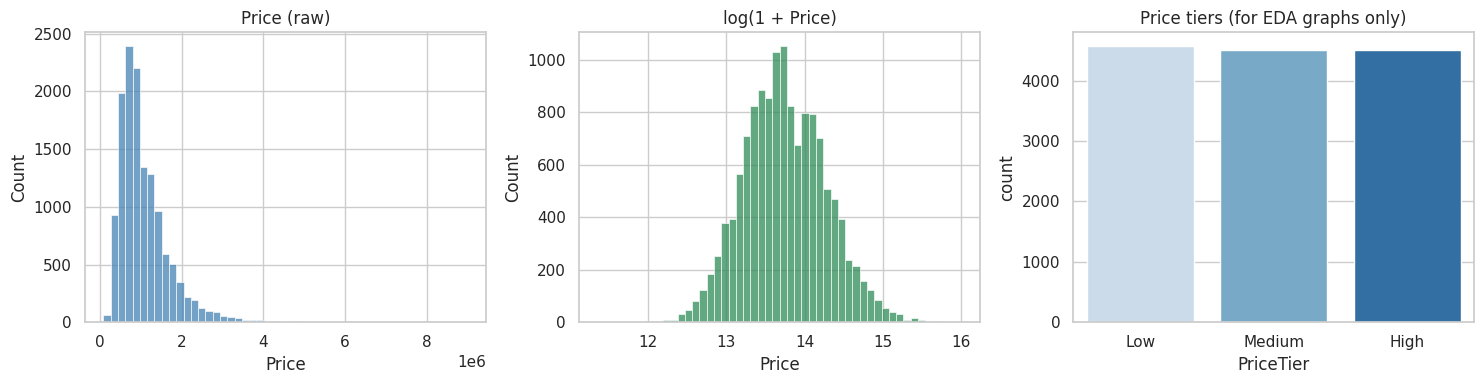

In [28]:
# Price tiers are used ONLY to colour graphs in EDA (not for modelling)
df["PriceTier"] = pd.qcut(df["Price"], 3, labels=["Low", "Medium", "High"])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["Price"], bins=50, ax=ax[0], color="steelblue")
ax[0].set_title("Price (raw)")
sns.histplot(np.log1p(df["Price"]), bins=50, ax=ax[1], color="seagreen")
ax[1].set_title("log(1 + Price)")
sns.countplot(x="PriceTier", data=df, ax=ax[2], palette="Blues")
ax[2].set_title("Price tiers (for EDA graphs only)")
plt.tight_layout()
plt.show()

In [29]:
print("Skewness raw Price :", round(df["Price"].skew(), 2))
print("Skewness log Price :", round(np.log1p(df["Price"]).skew(), 2))
df["Price"].describe().round(0)

Skewness raw Price : 2.24
Skewness log Price : 0.18


count      13579.0
mean     1075710.0
std       639327.0
min        85000.0
25%       650000.0
50%       903000.0
75%      1330000.0
max      9000000.0
Name: Price, dtype: float64

### Interpretation: Step 2

Price is **strongly right-skewed**: the mean (1,075,710) is clearly higher than the median (903,000), and the skewness is 2.24. A few very expensive properties (up to 9,000,000) create a long right tail. After the log transformation the skewness drops to 0.18, so the distribution becomes almost symmetric. This confirms the decision to use log(1 + Price) as the target in Assignment 2.

Because Price is numerical, the class-balance question of a Yes/No target does not apply. The Price tiers (Low: 4,571 properties up to 730,000, Medium: 4,502 properties, High: 4,506 properties above 1,181,000) are almost equal in size by construction and are used only to colour later graphs.

## Step 3: One Numerical Feature (Histogram): Distance

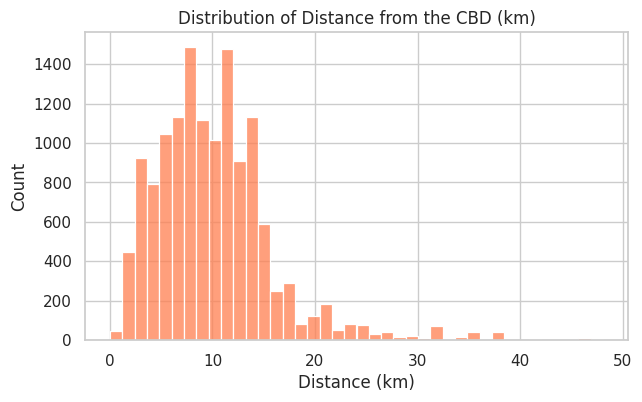

Mean  : 10.14
Median: 9.2
Skew  : 1.68


In [30]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Distance"], bins=40, color="coral")
plt.title("Distribution of Distance from the CBD (km)")
plt.xlabel("Distance (km)")
plt.show()

print("Mean  :", round(df["Distance"].mean(), 2))
print("Median:", round(df["Distance"].median(), 2))
print("Skew  :", round(df["Distance"].skew(), 2))

### Interpretation: Step 3

Distance from the CBD is **right-skewed** (skewness 1.68, mean 10.14 km, median 9.2 km). About 88% of the properties are within 15 km of the city centre, and only a few are far away (maximum 48.1 km). This means most sales happen in inner and middle suburbs, and the model will see few examples of distant properties. Distance is one of the columns that received a log transformation in the pipeline because of this skew.

## Step 4: One Numerical Feature (Density Plot): HouseAge

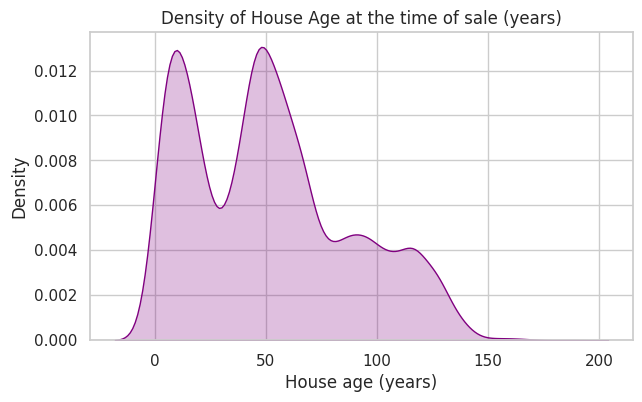

Houses with a known age: 8197 of 13579
Median age: 47.0


In [31]:
plt.figure(figsize=(7, 4))
sns.kdeplot(df["HouseAge"].dropna(), fill=True, color="purple")
plt.title("Density of House Age at the time of sale (years)")
plt.xlabel("House age (years)")
plt.show()

print("Houses with a known age:", df["HouseAge"].notna().sum(), "of", len(df))
print("Median age:", df["HouseAge"].median())

### Interpretation: Step 4

HouseAge is known for only 8,197 of 13,579 properties (about 60%). Its distribution is much more spread out than Distance: the median age is 47 years, the mean is 51.8 years and the skewness is only 0.52. About 10% of the houses are younger than 7 years and about 10% are older than 107 years. Among houses with a known age, 41.8% fall in the Established group, 25.9% in Historic, 17.1% in Modern and 15.2% in New. Since the skewness is small, no log transformation was needed for HouseAge, which matches the decision made in Assignment 2.

## Step 5: One Categorical Feature (Bar Chart): Type and Regionname

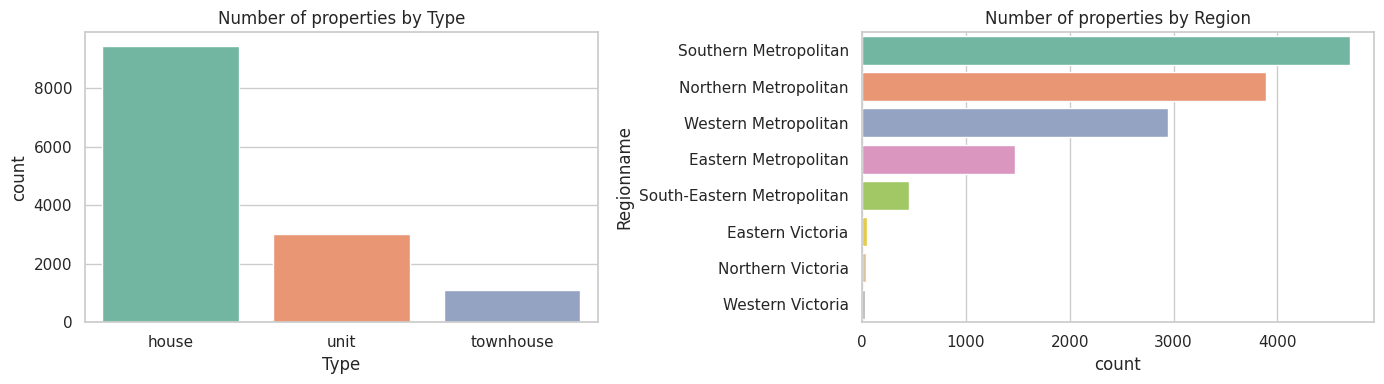

Type
house        69.6
unit         22.2
townhouse     8.2
Name: proportion, dtype: float64


In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x="Type", data=df, order=df["Type"].value_counts().index, ax=ax[0], palette="Set2")
ax[0].set_title("Number of properties by Type")
sns.countplot(y="Regionname", data=df, order=df["Regionname"].value_counts().index, ax=ax[1], palette="Set2")
ax[1].set_title("Number of properties by Region")
plt.tight_layout()
plt.show()

print(df["Type"].value_counts(normalize=True).round(3) * 100)

### Interpretation: Step 5

Houses make up 69.6% of the sales, units 22.2% and townhouses 8.2%, so Type is unbalanced. Among regions, Southern Metropolitan (34.6%), Northern Metropolitan (28.6%) and Western Metropolitan (21.7%) account for most of the data, while the three Victoria regions together have only 126 rows (less than 1%). The model will therefore learn the metropolitan regions well but will have little evidence for the rare ones, which is why rare categories were grouped as "infrequent" during encoding.

## Step 6: Spread and Outliers (Boxplot)

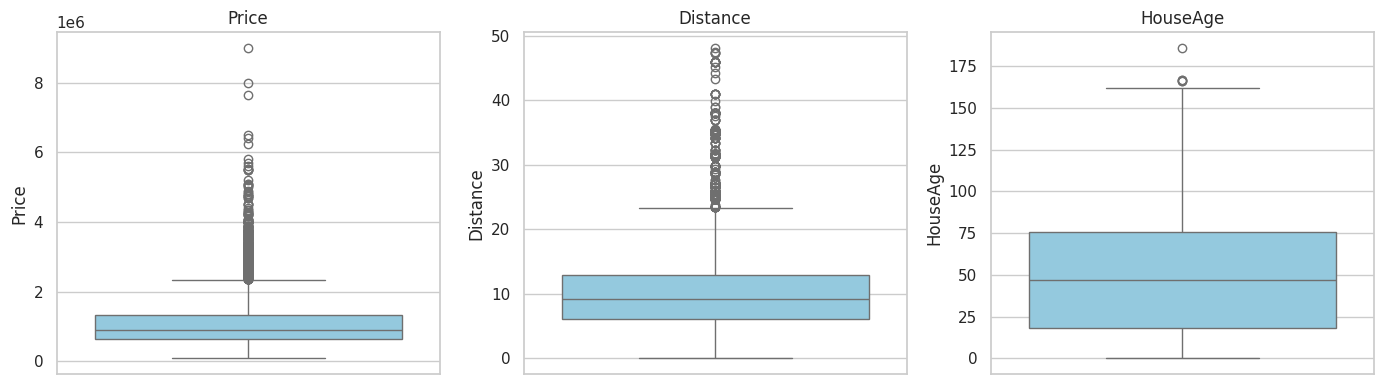

{'Price': 612, 'Distance': 411, 'HouseAge': 5}


In [33]:
cols = ["Price", "Distance", "HouseAge"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c in zip(ax, cols):
    sns.boxplot(y=df[c], ax=a, color="skyblue")
    a.set_title(c)
plt.tight_layout()
plt.show()

def iqr_count(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

print({c: iqr_count(df[c]) for c in cols})

### Interpretation: Step 6

The boxplots show many outliers on the high side. Price has 612 outliers above about 2,350,000 (the middle 50% of prices lie between 650,000 and 1,330,000, and the median is 903,000). Distance has 411 outliers above 23.4 km. HouseAge has only 5 outliers (above 163 years). These high prices are mostly genuine expensive properties, not errors, so they were capped rather than deleted in Assignment 2, and the skewness of Price was handled with a log transformation.

## Step 7: Feature vs Target (each feature compared with Price)

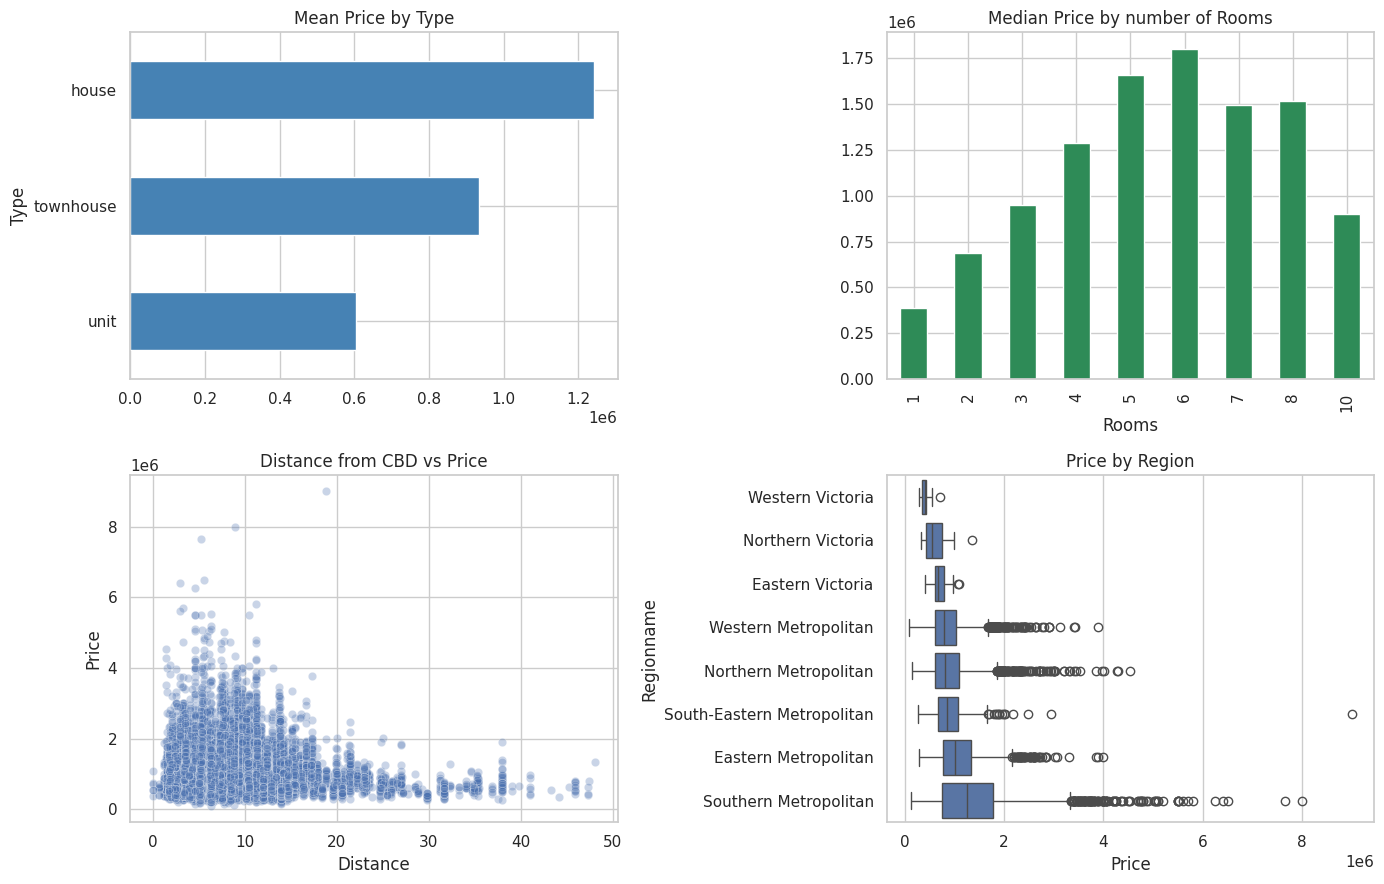

In [34]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

df.groupby("Type")["Price"].mean().sort_values().plot.barh(ax=ax[0, 0], color="steelblue")
ax[0, 0].set_title("Mean Price by Type")

df.groupby("Rooms")["Price"].median().plot.bar(ax=ax[0, 1], color="seagreen")
ax[0, 1].set_title("Median Price by number of Rooms")

sns.scatterplot(x="Distance", y="Price", data=df, alpha=0.3, ax=ax[1, 0])
ax[1, 0].set_title("Distance from CBD vs Price")

order = df.groupby("Regionname")["Price"].median().sort_values().index
sns.boxplot(y="Regionname", x="Price", data=df, order=order, ax=ax[1, 1])
ax[1, 1].set_title("Price by Region")

plt.tight_layout()
plt.show()

In [35]:
print(df.groupby("Type")["Price"].agg(["mean", "median", "count"]).round(0))
print()
print("Correlation Distance vs Price:", round(df["Distance"].corr(df["Price"]), 2))
print("Correlation Rooms vs Price   :", round(df["Rooms"].corr(df["Price"]), 2))

                mean     median  count
Type                                  
house      1242665.0  1080000.0   9449
townhouse   933927.0   847500.0   1113
unit        605127.0   560000.0   3017

Correlation Distance vs Price: -0.16
Correlation Rooms vs Price   : 0.5


### Interpretation: Step 7

All four comparisons show clear relationships with Price:
- **Type:** houses are the most expensive (mean 1,242,665), then townhouses (933,927) and units (605,127).
- **Rooms:** the median price rises steadily from 385,000 for 1 room to 1,660,000 for 5 rooms (correlation 0.50). The values for 7 to 10 rooms are based on very few properties (10, 8 and 1) and should not be trusted.
- **Distance:** the correlation is weak and negative (-0.16). The scatter plot shows that the highest prices occur close to the city, and prices become lower and less spread out farther away.
- **Region:** Southern Metropolitan has the highest median price (1,250,000), followed by Eastern Metropolitan (1,010,000). Western Metropolitan (793,000) and Northern Metropolitan (806,500) are lower. Western Victoria has the lowest median (400,000), but it has only 32 properties.

Type, Rooms and location (Region and Distance) are therefore useful features for predicting Price.

## Step 8: Feature vs Feature (Scatter Plot): BuildingArea vs Rooms

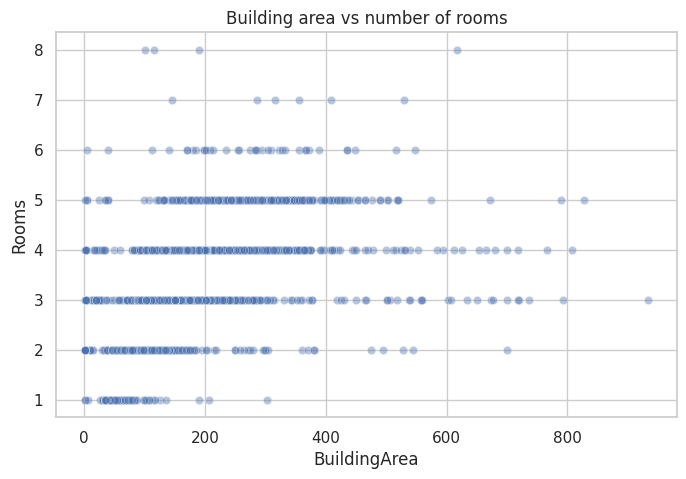

Rows used in the plot: 7104 of 13579
Correlation BuildingArea vs Rooms: 0.64


In [36]:
# BuildingArea has a few extreme values (data-entry errors), so the plot only shows areas below 1000 m2
sub = df[df["BuildingArea"] < 1000]

plt.figure(figsize=(8, 5))
sns.scatterplot(x="BuildingArea", y="Rooms", data=sub, alpha=0.4)
plt.title("Building area vs number of rooms")
plt.show()

print("Rows used in the plot:", len(sub), "of", len(df))
print("Correlation BuildingArea vs Rooms:", round(sub["BuildingArea"].corr(sub["Rooms"]), 2))

### Interpretation: Step 8

The scatter plot shows a clear upward pattern: larger buildings have more rooms (correlation 0.64). This is logical and shows that BuildingArea and Rooms carry related information. The plot uses 7,104 properties; the missing BuildingArea values cannot be plotted, and 8 extreme values of 1,000 m2 or more were left out, because they are likely data-entry errors and would squash the rest of the graph.

## Step 9: Many Feature Relationships (Correlation Heatmap)

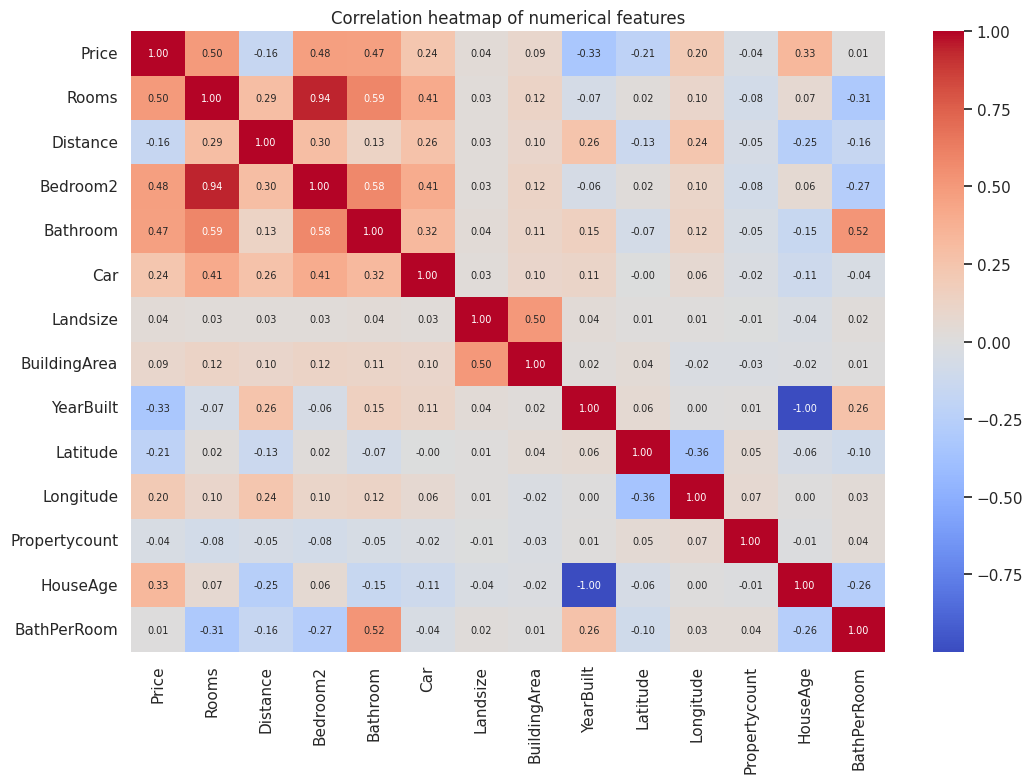

In [37]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation heatmap of numerical features")
plt.tight_layout()
plt.show()

In [38]:
print("Correlation of every feature with Price (strongest first):")
print(corr["Price"].drop("Price").sort_values(ascending=False).round(2))

Correlation of every feature with Price (strongest first):
Rooms            0.50
Bedroom2         0.48
Bathroom         0.47
HouseAge         0.33
Car              0.24
Longitude        0.20
BuildingArea     0.09
Landsize         0.04
BathPerRoom      0.01
Propertycount   -0.04
Distance        -0.16
Latitude        -0.21
YearBuilt       -0.33
Name: Price, dtype: float64


### Interpretation: Step 9

Features most related to Price are Rooms (0.50), Bedroom2 (0.48) and Bathroom (0.47), followed by HouseAge (0.33), Car (0.24) and Longitude (0.20). Distance (-0.16) and Latitude (-0.21) have weak negative correlations.

Some features are almost duplicates: YearBuilt and HouseAge have a correlation of -1.00 (HouseAge is calculated from YearBuilt), and Rooms and Bedroom2 have 0.94. Keeping both would add no new information and can hurt linear models.

BuildingArea (0.09) and Landsize (0.04) look almost unrelated to Price, but this is misleading. A few extreme values distort the Pearson correlation, which is very sensitive to outliers (see Step 10). Older houses (HouseAge) show a positive relation with Price. A possible reason is that many old houses are located in expensive inner suburbs, but this is only a guess; correlation does not prove that age itself raises the price.

## Step 10: Multiple Features Together (Multivariate View)

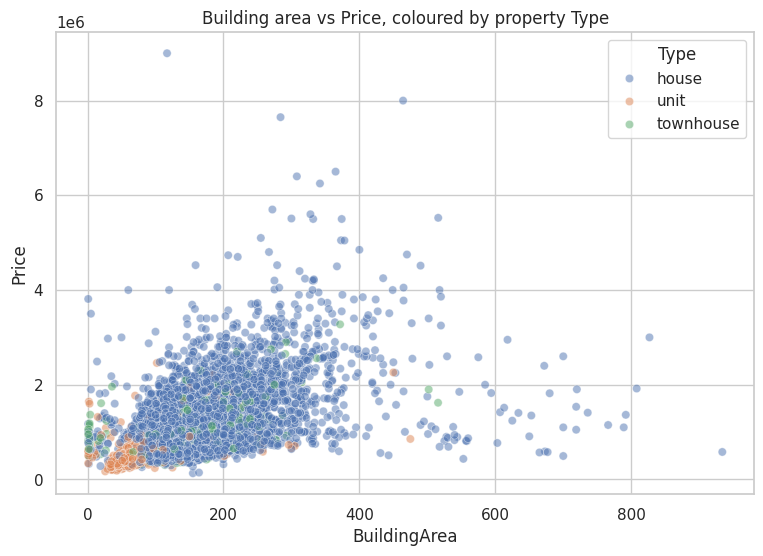

In [39]:
sub = df[df["BuildingArea"] < 1000]

plt.figure(figsize=(9, 6))
sns.scatterplot(x="BuildingArea", y="Price", hue="Type", data=sub, alpha=0.5)
plt.title("Building area vs Price, coloured by property Type")
plt.show()

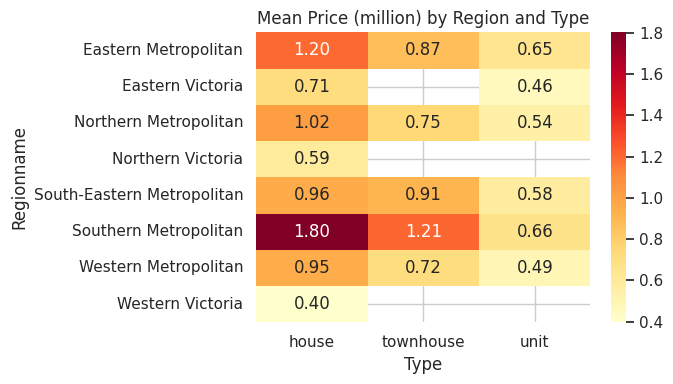

In [40]:
pv = df.pivot_table(values="Price", index="Regionname", columns="Type", aggfunc="mean")

plt.figure(figsize=(7, 4))
sns.heatmap(pv / 1e6, annot=True, fmt=".2f", cmap="YlOrRd")
plt.title("Mean Price (million) by Region and Type")
plt.tight_layout()
plt.show()

### Interpretation: Step 10

When the extreme building areas (1,000 m2 or more) are removed, BuildingArea and Price show a clear positive relation (correlation 0.56), much higher than the 0.09 seen in the heatmap. This shows how a few outliers can hide a real relationship. In the scatter plot, houses are generally higher in price than units and townhouses of similar size.

The region-by-type heatmap shows that **both Type and location matter together**. In every region, houses are more expensive than townhouses and units. But the same type costs very different amounts across regions: the mean price of a house is 1.80 million in Southern Metropolitan, 1.20 million in Eastern Metropolitan and only 0.95 million in Western Metropolitan. The empty cells (for example townhouses in the Victoria regions) mean that no such sales exist in the data.

## Step 11: Trends, Patterns and Anomalies

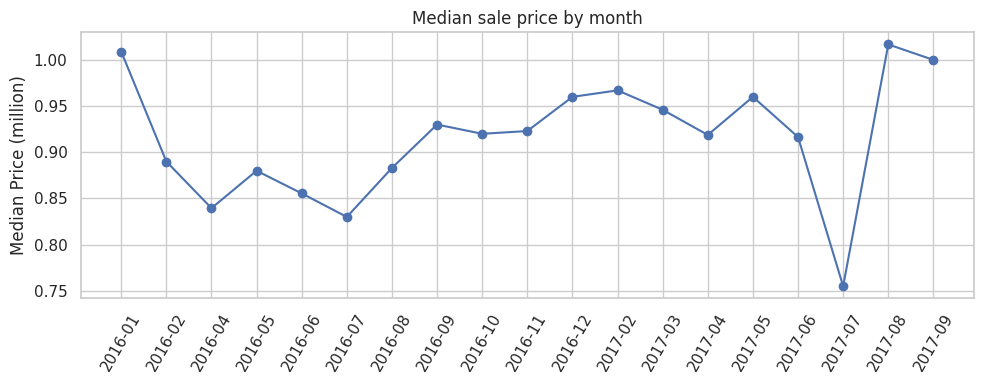

In [41]:
df["YearMonth"] = df["Date"].dt.to_period("M").astype(str)
trend = df.groupby("YearMonth")["Price"].median()

plt.figure(figsize=(10, 4))
plt.plot(trend.index, trend.values / 1e6, marker="o")
plt.xticks(rotation=60)
plt.ylabel("Median Price (million)")
plt.title("Median sale price by month")
plt.tight_layout()
plt.show()

In [42]:
print("Largest Landsize values:")
display(df.nlargest(3, "Landsize")[["Suburb", "Type", "Rooms", "Price", "Landsize"]])

print("Largest BuildingArea values:")
display(df.nlargest(3, "BuildingArea")[["Suburb", "Type", "Rooms", "Price", "BuildingArea"]])

print("Expensive properties with 2 or fewer rooms:")
display(df[(df["Rooms"] <= 2) & (df["Price"] > df["Price"].quantile(0.95))][["Suburb", "Type", "Rooms", "Price", "Distance"]].head())

Largest Landsize values:


,Suburb,Type,Rooms,Price,Landsize
11019,Fitzroy,house,3,2700000.0,433014.0
10503,Silvan,house,3,1085000.0,76000.0
687,Balwyn North,house,3,2000000.0,75100.0


Largest BuildingArea values:


,Suburb,Type,Rooms,Price,BuildingArea
13244,New Gisborne,house,5,1355000.0,44515.0
1484,Bulleen,house,4,1280000.0,6791.0
2560,Fitzroy North,townhouse,2,930000.0,3558.0


Expensive properties with 2 or fewer rooms:


,Suburb,Type,Rooms,Price,Distance
233,Armadale,unit,2,3625000.0,6.3
1682,Carlton North,house,2,2400000.0,3.2
2203,Eaglemont,house,2,2850000.0,10.3
3090,Hampton,house,1,2450000.0,13.7
3151,Hawthorn,house,2,2920000.0,4.6


### Interpretation: Step 11

**Trend:** the median monthly price moves between about 0.76 and 1.02 million, with no strong upward or downward trend. The data covers only January 2016 to September 2017, and the number of sales per month is very uneven: January 2016 has only 2 sales, February 2016 has 26, and March 2016 and January 2017 have none. July 2017 has the lowest median (0.755 million) but also the most sales (1,536), so monthly medians must be read carefully and should not be treated as a reliable price trend.

**Anomalies:**
- A 3-room house in Fitzroy (an inner suburb) is listed with a Landsize of 433,014 m2, which is almost certainly an error. Balwyn North (75,100 m2) is also suspicious.
- A 5-room house in New Gisborne has a BuildingArea of 44,515 m2, and a 2-room townhouse in Fitzroy North has 3,558 m2, which are also unrealistic.
- 18 properties with 2 or fewer rooms cost more than the 95th percentile (about 2.29 million), for example a 2-room unit in Armadale at 3,625,000. These are plausible: they are in expensive inner suburbs, so location explains the high price. They are unusual, not errors.

## Step 12: From EDA to Modeling Decisions

- **Target:** Price should be modelled on the log scale (skewness 2.24 reduced to 0.18).
- **Useful features:** Rooms/Bathroom, Type, location (Region, Distance, Latitude/Longitude, Suburb), HouseAge and BuildingArea (after outliers are handled) show a relationship with Price.
- **Redundant features:** YearBuilt and HouseAge (-1.00) and Rooms and Bedroom2 (0.94) carry the same information. Only HouseAge was used in the pipeline. For a linear model, one of Rooms and Bedroom2 should be dropped to avoid multicollinearity.
- **Outliers:** extreme Landsize and BuildingArea values should stay capped (or be checked and corrected), because they weaken correlations and can mislead a model.
- **Missing data:** BuildingArea (about 47.6%) and YearBuilt (about 39.6%) are missing in a large share of rows, so the missing-value flags created earlier are useful.
- **Rare categories:** the three Victoria regions have only 126 rows, and Suburb has 314 categories, so rare categories should stay grouped.
- **Evaluation:** because Price is numerical, accuracy is not suitable. Error measures such as RMSE or MAE and R2 should be used. Since the sales are spread unevenly over time, a time-based split would be more realistic than a random split.
- **Needs checking before final modelling:** impossible values such as the Fitzroy property with a land size of 433,014 m2.

## EDA Through the 3Cs Lens

**Character:** the graphs were interpreted honestly. The positive correlation between HouseAge and Price was not presented as proof that old age raises prices, and the monthly price changes were not called a trend because several months have very few sales.

**Courage:** the low correlations of BuildingArea (0.09) and Landsize (0.04) were questioned instead of being accepted. Checking the data showed that a few extreme values were hiding a real relationship (0.56 after removing them).

**Competence:** each plot was chosen for its purpose: histograms and density plots for distributions, boxplots for outliers, bar charts for categories, scatter plots and heatmaps for relationships, and a pivot heatmap for two categorical variables together. Every finding was linked back to the prediction of house prices.

## EDA Summary

The EDA followed the flow: target, single features, feature vs target, feature vs feature, multivariate view, and insights. Price is right-skewed and needs a log transformation. Type, number of rooms and location are the strongest drivers of price, and building size becomes important once extreme values are handled. Several features are redundant, and a few impossible values and outliers need care before modelling. These findings guide the feature selection, the handling of outliers and the evaluation method for the next modelling stage.